In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import json

from tensorflow.keras.models import load_model
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from PIL import Image
from IPython.display import display
import ipywidgets as widgets

In [3]:
model = load_model("model_B.keras")
print("Model B loaded successfully")

with open("labels.json", "r") as f:
    class_indices = json.load(f)

# Sort by class index so labels are always correct
class_names = [label for label, idx in sorted(class_indices.items(), key=lambda x: x[1])]

print("Class names:", class_names)
print("Model input shape:", model.input_shape)

Model B loaded successfully
Class names: ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']
Model input shape: (None, 192, 192, 3)


In [4]:
test_dir = "dataset/test"
IMG_SIZE = (192, 192)
BATCH_SIZE = 32

In [5]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)


test_ds = test_ds.map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(tf.data.AUTOTUNE)

Found 3068 files belonging to 7 classes.


In [6]:
display_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True
)

display_ds = display_ds.map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(tf.data.AUTOTUNE)

Found 3068 files belonging to 7 classes.


In [7]:
display_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True
)

display_ds = display_ds.map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(tf.data.AUTOTUNE)

Found 3068 files belonging to 7 classes.


In [8]:
def preprocess_image_for_model(img_path, target_size=IMG_SIZE):
    original_img = Image.open(img_path).convert("RGB")
    resized_img = original_img.resize(target_size)

    img_array = np.array(resized_img).astype("float32")
    img_array = np.expand_dims(img_array, axis=0)

    return original_img, img_array


def predict_image(model, img_path, class_names):
    original_img, img_array = preprocess_image_for_model(img_path)

    prediction = model.predict(img_array, verbose=0)
    predicted_class = np.argmax(prediction[0])
    predicted_label = class_names[predicted_class]
    confidence = prediction[0][predicted_class]

    return original_img, img_array, predicted_label, confidence, prediction

In [9]:
loss, accuracy = model.evaluate(test_ds)
print(f"Model B Accuracy: {accuracy*100:.2f}%")
print(f"Model B Loss: {loss:.4f}")

96/96 ━━━━━━━━━━━━━━━━━━━━ 23s 190ms/step - accuracy: 0.7914 - loss: 0.9219
Model B Accuracy: 79.14%
Model B Loss: 0.9219


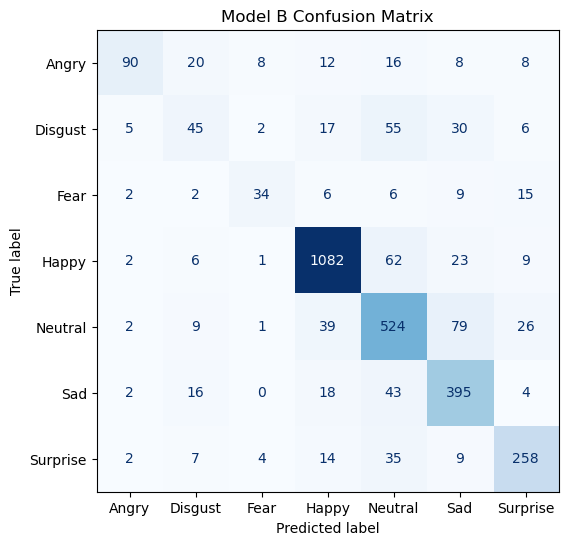

In [11]:
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_true_classes = np.argmax(y_true, axis=1)

y_pred = model.predict(test_ds, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)

cmatrix = confusion_matrix(y_true_classes, y_pred_classes)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cmatrix, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Model B Confusion Matrix")
plt.show()

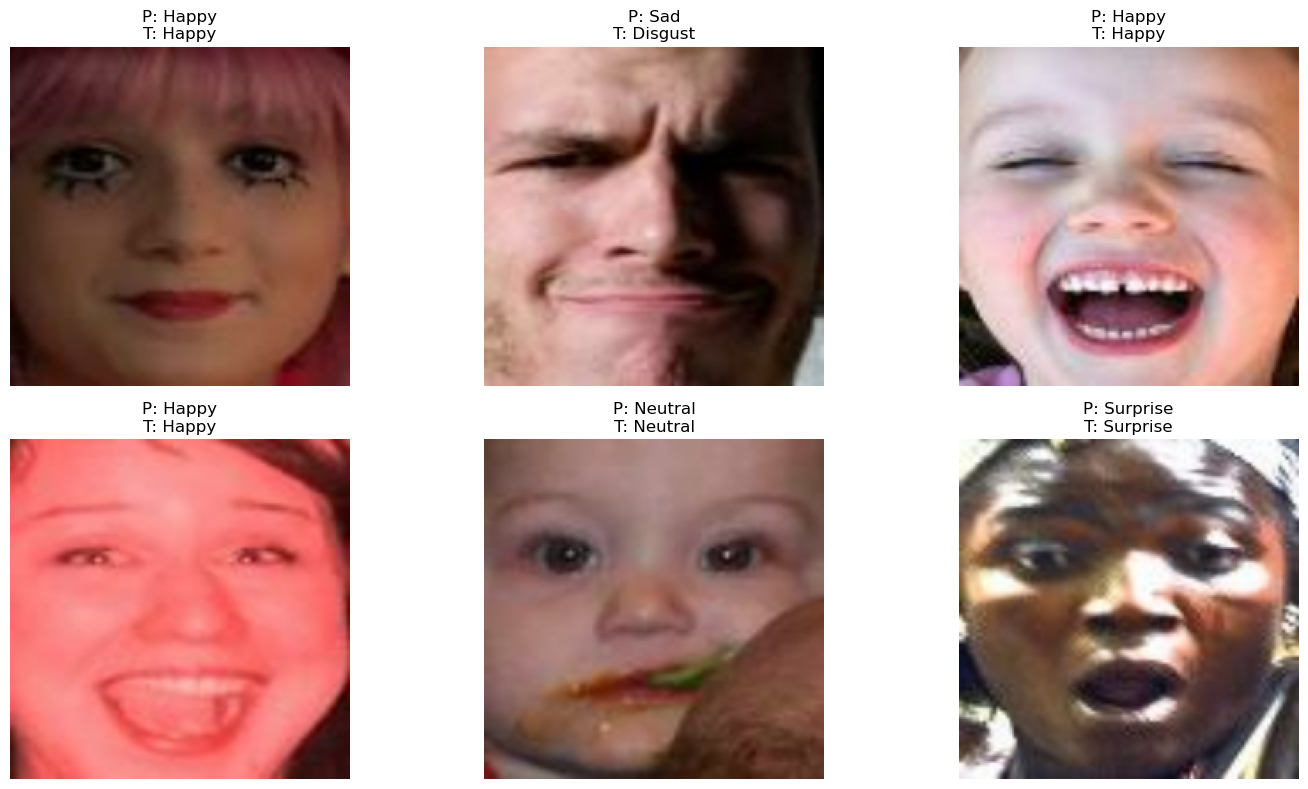

In [21]:
for images, labels_batch in display_ds.take(1):
    predictions = model.predict(images, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)
    true_classes = np.argmax(labels_batch.numpy(), axis=1)

    indices = np.random.choice(len(images), 6, replace=False)

    plt.figure(figsize=(15, 8))

    for plot_idx, img_idx in enumerate(indices):
        plt.subplot(2, 3, plot_idx + 1)
        img = tf.cast(images[img_idx], tf.uint8).numpy()
        plt.imshow(img)

        pred_label = class_names[predicted_classes[img_idx]]
        true_label = class_names[true_classes[img_idx]]

        plt.title(f"P: {pred_label}\nT: {true_label}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [13]:
def tta_predict_batch(model, images):
    pred_original = model.predict(images, verbose=0)

    images_flip = tf.image.flip_left_right(images)
    pred_flip = model.predict(images_flip, verbose=0)

    images_crop = tf.image.central_crop(images, central_fraction=0.9)
    images_crop = tf.image.resize(images_crop, IMG_SIZE)
    pred_crop = model.predict(images_crop, verbose=0)

    return (pred_original + pred_flip + pred_crop) / 3.0

In [14]:
all_preds = []
all_true = []

for images, labels in test_ds:
    preds = tta_predict_batch(model, images)
    all_preds.append(preds)
    all_true.append(labels.numpy())

y_pred_tta = np.concatenate(all_preds, axis=0)
y_true_tta = np.concatenate(all_true, axis=0)

y_pred_tta_classes = np.argmax(y_pred_tta, axis=1)
y_true_tta_classes = np.argmax(y_true_tta, axis=1)

tta_accuracy = np.mean(y_pred_tta_classes == y_true_tta_classes)
print(f"Model B + TTA Accuracy: {tta_accuracy*100:.2f}%")

Model B + TTA Accuracy: 79.86%


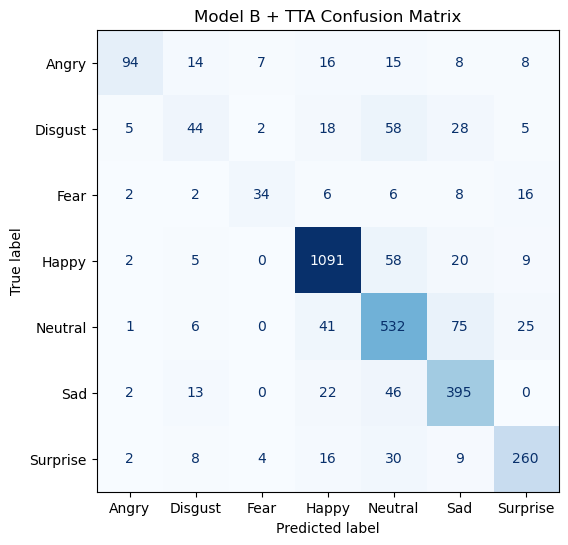

In [15]:
cm_tta = confusion_matrix(y_true_tta_classes, y_pred_tta_classes)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_tta, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Model B + TTA Confusion Matrix")
plt.show()

In [16]:
print(classification_report(
    y_true_tta_classes,
    y_pred_tta_classes,
    target_names=class_names
))

              precision    recall  f1-score   support

       Angry       0.87      0.58      0.70       162
     Disgust       0.48      0.28      0.35       160
        Fear       0.72      0.46      0.56        74
       Happy       0.90      0.92      0.91      1185
     Neutral       0.71      0.78      0.75       680
         Sad       0.73      0.83      0.77       478
    Surprise       0.80      0.79      0.80       329

    accuracy                           0.80      3068
   macro avg       0.75      0.66      0.69      3068
weighted avg       0.79      0.80      0.79      3068



In [17]:
print("Final Summary")
print("-" * 40)
print(f"Model B Accuracy      : {accuracy*100:.2f}%")
print(f"Model B + TTA Accuracy: {tta_accuracy*100:.2f}%")

Final Summary
----------------------------------------
Model B Accuracy      : 79.14%
Model B + TTA Accuracy: 79.86%


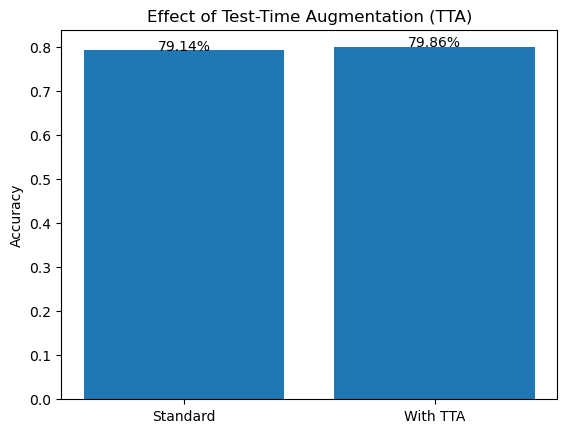

In [20]:
import matplotlib.pyplot as plt

models = ['Standard', 'With TTA']
accuracies = [0.7914, 0.7986]

plt.figure()
plt.bar(models, accuracies)
plt.title("Effect of Test-Time Augmentation (TTA)")
plt.ylabel("Accuracy")

for i, v in enumerate(accuracies):
    plt.text(i, v + 0.001, f"{v:.2%}", ha='center')

plt.show()

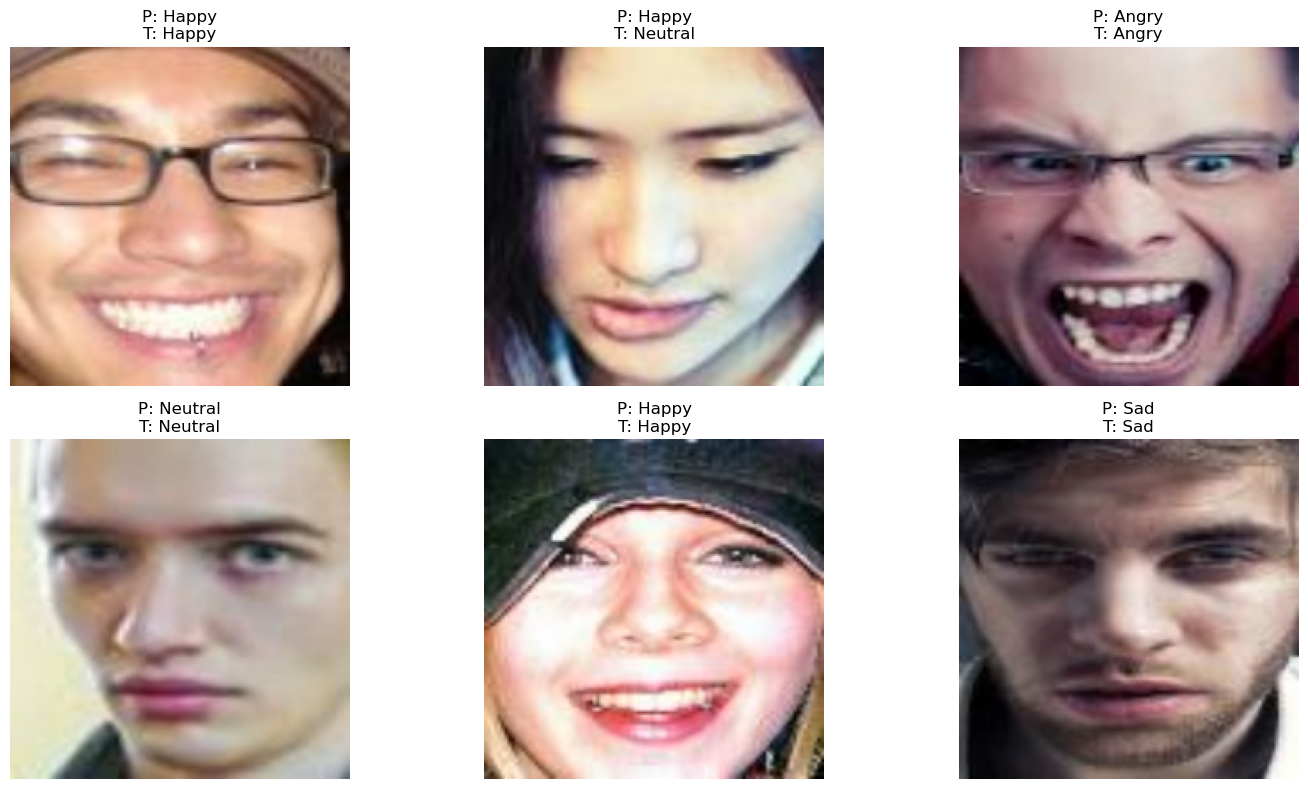

In [18]:
upload = widgets.FileUpload(accept='image/*', multiple=False)
display(upload)

FileUpload(value=(), accept='image/*', description='Upload')

Saved as shared_input.jpg
Original filename: WIN_20260405_19_20_02_Pro.jpg


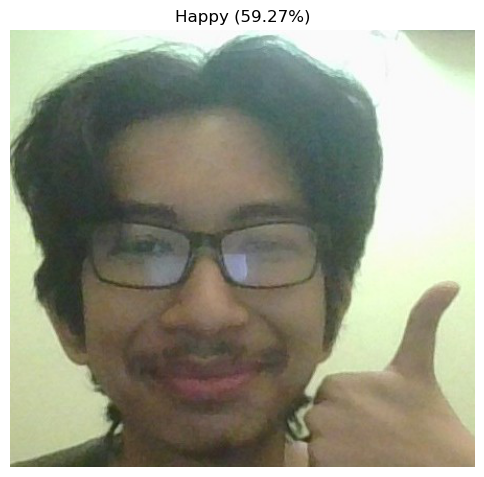

In [23]:
uploaded_file = list(upload.value)[0]
content = uploaded_file["content"]
filename = uploaded_file["name"]

with open("shared_input.jpg", "wb") as f:
    f.write(content)

print("Saved as shared_input.jpg")
print("Original filename:", filename)

original_img, img_array, predicted_label, confidence, prediction = predict_image(
    model,
    "shared_input.jpg",
    class_names
)

plt.figure(figsize=(6, 6))
plt.imshow(original_img)
plt.title(f"{predicted_label} ({confidence*100:.2f}%)")
plt.axis("off")
plt.show()

In [24]:
augmentation_layer = None
backbone_model = None
backbone_index = None

for i, layer in enumerate(model.layers):
    if "augmentation" in layer.name.lower():
        augmentation_layer = layer
    if isinstance(layer, tf.keras.Model) and "efficientnet" in layer.name.lower():
        backbone_model = layer
        backbone_index = i
        break

if backbone_model is None:
    raise ValueError("EfficientNet backbone not found inside Model B.")

head_layers = model.layers[backbone_index + 1:]

print("Augmentation layer:", augmentation_layer.name if augmentation_layer else "None")
print("Backbone:", backbone_model.name)
print("Head layers:", [layer.name for layer in head_layers])

Augmentation layer: augmentation
Backbone: efficientnetv2-b1
Head layers: ['global_average_pooling2d', 'batch_normalization', 'dense', 'dropout', 'dense_1', 'dropout_1', 'dense_2']


In [25]:
conv_types = (
    tf.keras.layers.Conv2D,
    tf.keras.layers.DepthwiseConv2D,
    tf.keras.layers.SeparableConv2D
)

last_conv_layer = None
for layer in reversed(backbone_model.layers):
    if isinstance(layer, conv_types):
        last_conv_layer = layer
        break

if last_conv_layer is None:
    raise ValueError("No convolutional layer found inside backbone.")

print("Last conv layer:", last_conv_layer.name)

Last conv layer: top_conv


In [26]:
backbone_cam_model = tf.keras.Model(
    inputs=backbone_model.input,
    outputs=[last_conv_layer.output, backbone_model.output]
)

In [27]:
def apply_head(x, head_layers):
    for layer in head_layers:
        if isinstance(layer, (tf.keras.layers.Dropout, tf.keras.layers.BatchNormalization)):
            x = layer(x, training=False)
        else:
            x = layer(x)
    return x

In [28]:
def make_gradcam_heatmap(img_array, augmentation_layer, backbone_cam_model, head_layers):
    img_tensor = tf.convert_to_tensor(img_array, dtype=tf.float32)

    if augmentation_layer is not None:
        x = augmentation_layer(img_tensor, training=False)
    else:
        x = img_tensor

    with tf.GradientTape() as tape:
        conv_outputs, backbone_outputs = backbone_cam_model(x, training=False)
        tape.watch(conv_outputs)

        preds = apply_head(backbone_outputs, head_layers)
        pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()

In [29]:
heatmap = make_gradcam_heatmap(
    img_array,
    augmentation_layer,
    backbone_cam_model,
    head_layers
)

print("Grad-CAM heatmap generated")

Grad-CAM heatmap generated


C:\Users\User\AppData\Local\Temp\ipykernel_14368\2008682328.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


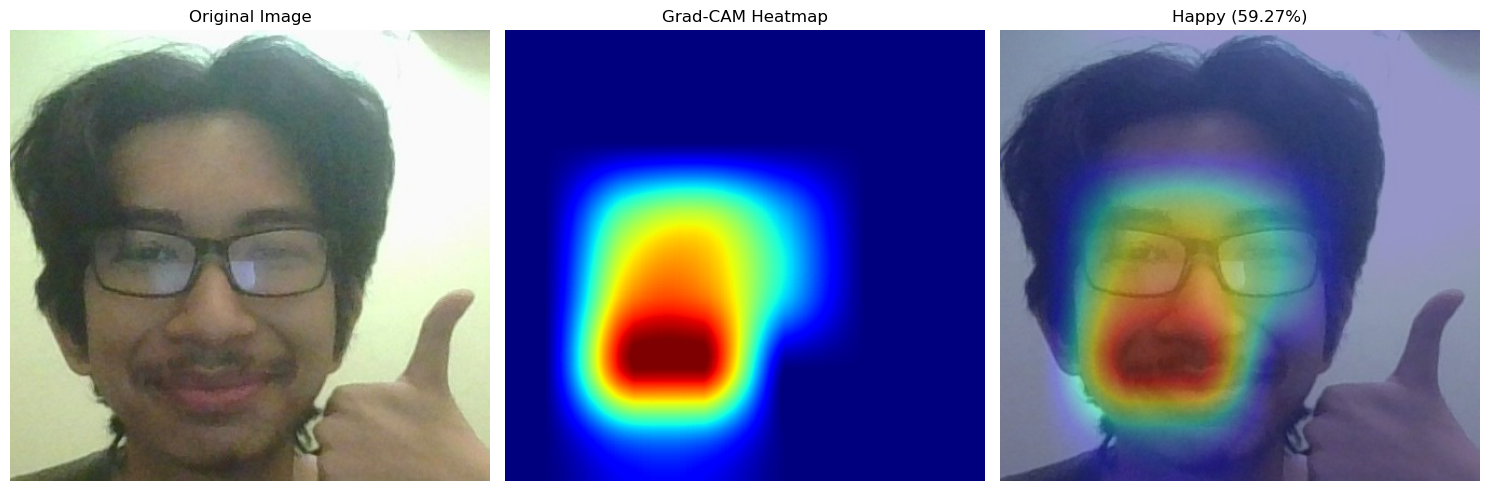

In [30]:
def display_gradcam(original_img, heatmap, predicted_label, confidence):
    heatmap_img = Image.fromarray(np.uint8(255 * heatmap))
    heatmap_img = heatmap_img.resize(original_img.size)

    heatmap_array = np.array(heatmap_img) / 255.0
    jet = cm.get_cmap("jet")
    colored_heatmap = jet(heatmap_array)[:, :, :3]

    original_array = np.array(original_img).astype("float32") / 255.0
    overlay = np.clip(0.6 * original_array + 0.4 * colored_heatmap, 0, 1)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(original_img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_array, cmap="jet")
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title(f"{predicted_label} ({confidence*100:.2f}%)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

display_gradcam(original_img, heatmap, predicted_label, confidence)